# GFuNK context and a deliberately small spectral surrogate

What can a simple spectral fit teach us about representation, transfer and the limits of a research analogy?

Fall 2024.


# A baseline, not GFuNK
Predict whether a fit to three heat modes at one diffusivity can recover a fourth mode or a changed diffusivity. Keep those questions separate from using more samples of the same function.

In [1]:
import numpy as np
from operator_bench import dataset,fit,predict,field,metrics
from demo import run
from IPython.display import SVG,display
train=dataset(seed=1801)
model=fit(train["initial"],train["final"])
print("Fitted gains:",model["gains"])

Fitted gains: [0.90601806 0.67382545 0.41136911]


## Implement a scalar gain
Complete the numerator. The denominator guard rejects an unexcited input mode. This guided check is distinct from the assigned data.

In [2]:
def my_gain(a,b):
    a=np.asarray(a,float);b=np.asarray(b,float)
    denominator=np.dot(a,a)
    if denominator<=0:
        raise ValueError("Unexcited mode")
    numerator=None  # TODO: sum of input times output
    return None if numerator is None else numerator/denominator
trial=my_gain([0.5,-1,1.5],[0.3,-0.6,0.9])
if trial is None:
    print("Complete the numerator, then rerun.")
else:
    np.testing.assert_allclose(trial,0.6,rtol=0,atol=1e-14)
    print("Guided gain check passed:",trial)

Complete the numerator, then rerun.


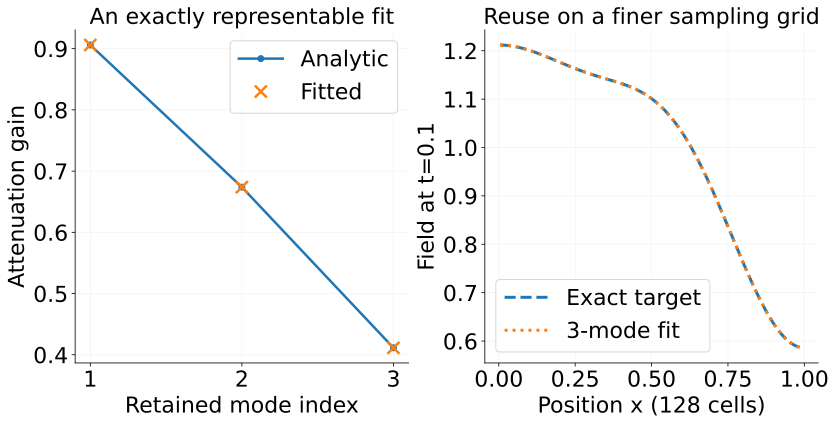

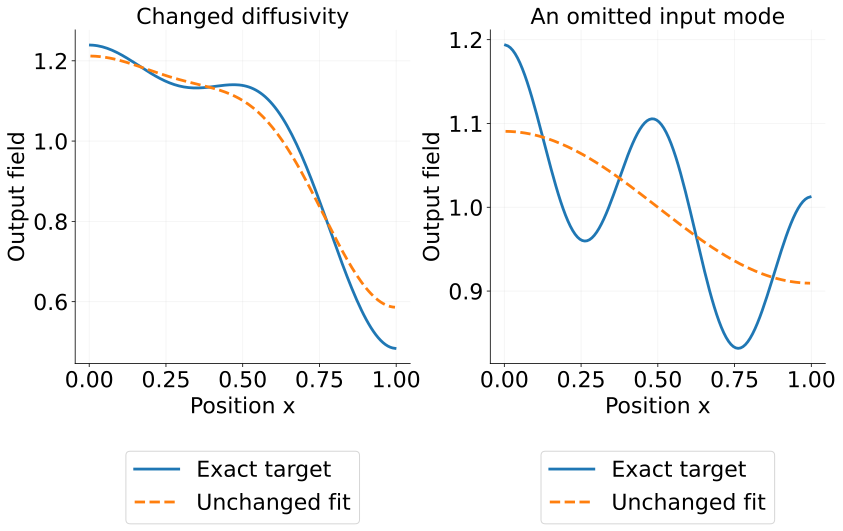

Same-family grid errors: [1.450951033521181e-16, 1.0700305451613401e-16, 1.833310494526958e-16, 1.519341277825554e-16]
Changed-parameter error: {'rms': 0.043135726840657036, 'relative_l2': 0.041969054972006516, 'max_error': 0.10241358163108727, 'mean_error': 7.461688261201196e-18}


In [3]:
results=run()
display(SVG(filename="spectral-baseline.svg"))
display(SVG(filename="transfer-failures.svg"))
print("Same-family grid errors:",results["same_family_grid_errors"])
print("Changed-parameter error:",results["changed_parameter_error"])

## Modify input bandwidth
Add a fourth cosine amplitude of0.3 to a mean-one input. Predict the mean error and whether field error vanishes. The model still retains only three modes.

In [4]:
coeff=np.array([1.,0.1,0.,0.,0.3])
initial=field(coeff,128,T=0)
target=field(coeff,128)
predicted=predict(model,initial)
print(metrics(predicted,target))

{'rms': 0.04373165367146907, 'relative_l2': 0.043600682067196715, 'max_error': 0.06177140163485206, 'mean_error': 1.028700485375712e-17}


Write a precise claim about the successful grid evaluation and a separate statement about the missing-mode failure. Explain why neither result reproduces the current GFuNK paper. Optional: enlarge the retained basis and regenerate training inputs that excite the new mode.